# Modeling Human Activity States with Hidden Markov Models

**Use case:** elderly fall-risk and inactivity monitoring.

This notebook currently implements phases 1–4: pilot inspection, data quality,
preprocessing, visualisation, and a fixed recording-level train/test split. A from-scratch HMM and unseen-data evaluation
are planned for later phases. Jumping is an impact activity, not verified fall data.

**Current readiness is computed at the end.** Valid clips can be inspected while
invalid or unverified sessions are excluded from supervised training. Dataset readiness and mandatory
video evidence must both be resolved before claiming the collection is complete.

## 1. Setup & Data Loading

Recordings were made with **Sensor Logger** (Android, Infinix X6855). Each export is a folder with one CSV per sensor. Each CSV has `time` (ns since the Unix epoch), `seconds_elapsed`, and the axes in the order `z, y, x`. A `Metadata.csv` file records the device and the configured sample rates.

Two streams are used:

| Stream | File | Units | Why |
|---|---|---|---|
| Accelerometer | `TotalAcceleration.csv` | m/s² | The true accelerometer reading, **including gravity**. The app's `Accelerometer.csv` has gravity removed, which would discard the orientation cue that separates *still* (phone flat) from *standing* (phone upright). |
| Gyroscope | `Gyroscope.csv` | rad/s | Calibrated angular velocity (bias-corrected). |

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if not (ROOT / "Plan.md").exists():
    raise RuntimeError("Start Jupyter from the repository root or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RAW_DIR = ROOT / "data/raw"
PROCESSED_DIR = ROOT / "data/processed"
LABELS_DIR = ROOT / "data/labels"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

### 1.1 Loading utilities

The reusable implementation is in `scripts/preprocessing.py`. It is shared with
the command-line pipeline and regression checks, so the notebook and exported
CSVs use the same cleaning rules. Raw exports remain unchanged. Timestamps are
sorted; exact duplicate samples are counted and removed. Conflicting duplicates,
non-finite readings, and malformed timestamps fail validation.

In [2]:
from scripts.preprocessing import (
    ACTIVITIES, SENSOR_FILES, TARGET_FS, SIGNALS,
    load_metadata, load_sensor, load_recording, sampling_stats,
    gap_intervals, harmonise_recording, trim_clip, label_session,
    save_processed, build_dataset, require_training_ready, load_labelled_sequences,
)

### 1.2 Pilot check

Before the main collection, four short pilot recordings were made to check the data format:

| Pilot | Phone | Question it answers |
|---|---|---|
| `pilot_01_flat` | Flat on a table | Is gravity included? Which axis carries it when flat? |
| `pilot_02_upright` | Held at waist level (the grip used for standing, walking, jumping) | Which axis carries gravity when upright? |
| `pilot_03_walk` | Same grip, walking | Data quality during movement |
| `pilot_04_flat_50hz` | Flat, app set to a lower rate | Does the rate setting change the delivered rate? |

In [3]:
pilots = [load_recording(p) for p in sorted((RAW_DIR / "pilot").iterdir()) if p.is_dir()]

print(f"Device: {pilots[0]['meta']['device']}  |  {pilots[0]['meta']['platform']}  |  Sensor Logger {pilots[0]['meta']['app_version']}")
pilot_rates = pd.DataFrame([
    {"recording": rec["name"], "sensor": sensor,
     "configured_hz": rec["meta"]["configured_hz"][sensor], **sampling_stats(rec[sensor])}
    for rec in pilots for sensor in SENSOR_FILES
]).set_index(["recording", "sensor"])
pilot_rates

Device: Infinix X6855  |  android 36  |  Sensor Logger 1.68


configured_hz  n_samples  duration_s  measured_hz  \
recording          sensor                                                      
pilot_01_flat      acc             100.0        574       9.804       58.445   
                   gyro            100.0        575       9.825       58.445   
pilot_02_upright   acc             100.0        736      12.575       58.448   
                   gyro            100.0        739      12.635       58.448   
pilot_03_walk      acc             100.0        898      15.342       58.452   
                   gyro            100.0        897      15.329       58.452   
pilot_04_flat_50hz acc              50.0        528      18.031       29.227   
                   gyro             50.0        529      18.066       29.227   

                           median_dt_ms  jitter_ms  normal_interval_jitter_ms  \
recording          sensor                                                       
pilot_01_flat      acc           17.110  1.517e-04                  1.517e-04   
                   gyro          17.110  1.784e-01                  1.784e-01   
pilot_02_upright   acc           17.109  1.330e-04                  1.330e-04   
                   gyro          17.109  3.147e-01                  3.147e-01   
pilot_03_walk      acc           17.108  1.427e-01                  1.427e-01   
                   gyro          17.108  1.627e-04                  1.627e-04   
pilot_04_flat_50hz acc           34.215  1.718e-04                  1.718e-04   
                   gyro          34.215  1.809e-04                  1.809e-04   

                           max_dt_ms  dropped  large_gaps  duplicates_removed  
recording          sensor                                                      
pilot_01_flat      acc        17.110        0           0                   0  
                   gyro       21.387        0           0                   0  
pilot_02_upright   acc        17.110        0           0                   0  
                   gyro       25.664        0           0                   0  
pilot_03_walk      acc        17.109        0           0                   0  
                   gyro       17.109        0           0                   0  
pilot_04_flat_50hz acc        34.216        0           0                   0  
                   gyro       34.216        0           0                   0

In [4]:
def stream_offset_ms(rec):
    """Start-time difference between the gyroscope and accelerometer streams (ms)."""
    return (rec["gyro"]["t"].iloc[0] - rec["acc"]["t"].iloc[0]) * 1e3


def shared_timestamps(rec):
    """Fraction of accelerometer timestamps that also appear in the gyroscope stream."""
    return np.isin(rec["acc"]["timestamp_ns"], rec["gyro"]["timestamp_ns"]).mean()


pd.DataFrame([
    {"recording": rec["name"], "gyro_start_offset_ms": stream_offset_ms(rec),
     "shared_timestamps": shared_timestamps(rec)}
    for rec in pilots
]).set_index("recording")

,gyro_start_offset_ms,shared_timestamps
recording,,
pilot_01_flat,-17.110,0.0
pilot_02_upright,-17.109,0.0
pilot_03_walk,17.108,0.0
pilot_04_flat_50hz,-17.108,0.0


In [5]:
def steady(df, trim_s=1.0):
    """Drop the first and last trim_s seconds (button-press and settling artefacts)."""
    t = df["t"]
    return df[(t > t.iloc[0] + trim_s) & (t < t.iloc[-1] - trim_s)]


def magnitude(df):
    """Euclidean norm of the x, y, z columns."""
    return np.sqrt(df["x"] ** 2 + df["y"] ** 2 + df["z"] ** 2)


orientation = pd.DataFrame([
    {"recording": rec["name"],
     **{f"mean_acc_{ax}": steady(rec["acc"])[ax].mean() for ax in "xyz"},
     "mean_|a|": magnitude(steady(rec["acc"])).mean(),
     "std_|a|": magnitude(steady(rec["acc"])).std(),
     "std_|w|": magnitude(steady(rec["gyro"])).std()}
    for rec in pilots
]).set_index("recording")
orientation

,mean_acc_x,mean_acc_y,mean_acc_z,mean_|a|,std_|a|,std_|w|
recording,,,,,,
pilot_01_flat,-0.081,0.578,9.819,9.836,0.007,4.311e-04
pilot_02_upright,0.369,9.843,1.286,9.944,0.142,1.044e-01
pilot_03_walk,0.299,9.857,1.094,9.992,0.852,4.798e-01
pilot_04_flat_50hz,-0.137,0.502,9.826,9.840,0.048,6.309e-03


### 1.3 Pilot findings

- `TotalAcceleration` contains gravity: flat-on-table z is approximately 9.8 m/s²;
  the waist-level pilot places most gravity on y. This makes orientation a useful
  cue under this collection protocol, not proof of generalisation to other grips.
- The 100 Hz setting delivers approximately 58.4 Hz and the 50 Hz setting delivers
  approximately 29.2 Hz. These are measured results for this device; they do not
  establish the cause of the app/hardware rate difference.
- Pilot jitter reaches approximately 0.315 ms, with no intervals above three times
  the median. These pilot findings must not be extended to the training sessions.
- Sensors have offset sampling instants and no shared timestamps in these pilots.
  This does not by itself imply separate hardware clocks.
- A common 25 Hz grid avoids upsampling either source. Its 12.5 Hz Nyquist covers
  the observed activity fundamentals; a 10 Hz low-pass filter attenuates higher
  frequencies, including some impact detail. The filter is not an ideal brick wall.

## 2. Pre-processing & Sampling-Rate Harmonisation

Each native stream is filtered using a fourth-order, zero-phase Butterworth
low-pass at 10 Hz (implemented as second-order sections for numerical stability).
Both filtered streams are interpolated **once** onto the same integer-nanosecond
25 Hz grid, restricted to shared coverage.

Intervals exceeding three times the median sampling interval split a session **before filtering**. The union of both sensors' gaps defines independent blocks. Blocks shorter than seven seconds are discarded; one second is trimmed from both ends of each remaining block after filtering. No values, durations or transitions are inferred across an outage. A whole-recording resampling request still rejects gaps.

**No-re-recording decision (29 Oct):** keep 52 labelled clips and recover continuous session blocks without labels. The participant has no session footage or exact timer records; roughly 15-second timing cannot verify boundaries. The original session labels remain provisional and do not enter supervised training. Phase 4 now reserves eight single-activity clips for testing; only the other 44 may initialise supervised emissions. Phone orientation is retained as recorded, including the different session-1 grip. Two labelled training sessions were a plan choice; two unseen test files remain required later.

Clips retain at least one second of exclusion at each end. Reviewed signal-based
crop intervals in `data/clip_intervals.csv` remove additional quiet lead-ins and
handling artifacts and cap each clip at 10 seconds. SHA-256 fingerprints bind
these decisions to the recordings inspected. Original single-activity labels are
retained; signal inspection is not a substitute for the required videos.

`timestamp_ns` is always Unix epoch nanoseconds. `seconds_elapsed` is always
relative to the **original recording start**, including after cropping; it need
not start at zero. Crop offsets remain traceable to the original data.

### 2.1 Build and validate the available dataset

The pipeline regenerates metadata (including pilots), sampling/gap reports, valid
processed files, independent unlabelled session blocks, crop provenance and `data/quality/status.json`. It removes stale
CSV files from its generated training output directories. Raw recordings and
original session labels remain untouched.

A session additionally needs contiguous valid segment labels and a matching
`verified` entry in `data/session_review.csv`, based on real timing/footage and
phone-placement evidence. Neither the pipeline nor an inferred signal pattern can
supply that ground truth.

In [6]:
result = build_dataset(ROOT, output_dir=PROCESSED_DIR)
all_recs = [r for r in result["records"] if r["rec_type"] in ("clip", "session")]
clips = [r for r in all_recs if r["rec_type"] == "clip"]
sessions = [r for r in all_recs if r["rec_type"] == "session"]
processed_clips = [r for r in result["accepted"] if r["rec_type"] == "clip"]
processed_sessions = [r for r in result["accepted"] if r["rec_type"] == "session"]
training_clips = [r for r in processed_clips if r["split"] == "train"]
test_clips = [r for r in processed_clips if r["split"] == "test"]
qdf = result["quality"]
print(f"Accepted {len(processed_clips)}/52 clips; {len(processed_sessions)} verified labelled sessions; {len(result['unlabelled'])} unlabelled session blocks")
display(result["rejected"][["recording", "reason"]] if not result["rejected"].empty else "No rejected recordings")
print(f"Fixed split: {len(training_clips)} training clips; {len(test_clips)} held-out test clips")

Accepted 52/52 clips; 0 verified labelled sessions; 4 unlabelled session blocks


,recording,reason
0,train_session_01,acc: 2 large gaps (max 6.544s); gyro: 2 large ...
1,train_session_02,acc: 2 large gaps (max 87.533s); gyro: 2 large...


Fixed split: 44 training clips; 8 held-out test clips


### 2.2 Sampling quality and report table

The following table is computed from **every stream**, not entered by hand. Full
jitter includes gaps. Normal-interval jitter is a separate diagnostic, never a
replacement for reporting outages. `duration_s` is timestamp span, which can
include missing time; only accepted clips contribute to the duration requirement.

In [7]:
rate_table = qdf[["recording", "type", "sensor", "configured_hz", "measured_hz",
                  "duration_s", "jitter_ms", "normal_interval_jitter_ms",
                  "max_dt_ms", "large_gaps", "duplicates_removed"]].copy()
accepted_names = {r["name"] for r in result["accepted"]}
rate_table["split"] = rate_table.recording.map({r["name"]: r["split"] for r in result["records"]})
rate_table["harmonised_hz"] = np.where(rate_table.recording.isin(accepted_names), TARGET_FS, np.nan)
rate_table["disposition"] = np.where(rate_table.recording.isin(accepted_names), "accepted",
                                   np.where(rate_table.type == "pilot", "pilot only", "excluded"))
rate_table.to_csv(ROOT / "data/quality/sampling_rate_report.csv", index=False)
display(rate_table)
display(pd.read_csv(ROOT / "data/quality/gaps.csv"))

,recording,type,sensor,configured_hz,measured_hz,duration_s,jitter_ms,normal_interval_jitter_ms,max_dt_ms,large_gaps,duplicates_removed,split,harmonised_hz,disposition
0,jumping_01,clip,acc,100.0,58.446,12.815,1.567e-04,1.567e-04,17.110,0,0,train,25.0,accepted
1,jumping_01,clip,gyro,100.0,58.446,12.837,1.561e-01,1.561e-01,21.387,0,0,train,25.0,accepted
2,jumping_02,clip,acc,100.0,58.446,12.028,1.508e-04,1.508e-04,17.110,0,0,test,25.0,accepted
3,jumping_02,clip,gyro,100.0,58.446,12.028,1.530e-04,1.530e-04,17.110,0,0,test,25.0,accepted
4,jumping_03,clip,acc,100.0,58.447,10.330,1.739e-01,1.739e-01,17.110,0,0,train,25.0,accepted
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,pilot_04_flat_50hz,pilot,gyro,50.0,29.227,18.066,1.809e-04,1.809e-04,34.216,0,0,pilot,NaN,pilot only
112,train_session_01,session,acc,100.0,58.455,137.782,9.446e+01,1.895e-04,6543.599,2,0,train,NaN,excluded
113,train_session_01,session,gyro,100.0,58.455,137.791,9.447e+01,1.113e-01,6560.707,2,0,train,NaN,excluded
114,train_session_02,session,acc,100.0,58.454,114.019,2.225e+03,1.660e-04,87532.872,2,0,train,NaN,excluded


,recording,sensor,start_s,end_s,gap_s
0,train_session_01,acc,44.978,49.828,4.850
1,train_session_01,acc,79.646,86.190,6.544
2,train_session_01,gyro,44.987,49.815,4.829
3,train_session_01,gyro,79.637,86.198,6.561
4,train_session_02,acc,0.057,0.129,0.073
5,train_session_02,acc,25.397,112.930,87.533
6,train_session_02,gyro,0.044,0.108,0.064
7,train_session_02,gyro,25.401,112.917,87.516


### 2.3 Verify both native rates against the common grid

Pilots at both settings exercise the same filter and resampling code without
becoming training data. Integer timestamp differences must be exactly 40,000,000 ns.

In [8]:
for rec in pilots:
    aligned = harmonise_recording(rec)
    assert np.all(np.diff(aligned.timestamp_ns) == 40_000_000)
    assert np.isfinite(aligned[SIGNALS]).all().all()
    print(f"{rec['name']}: configured {rec['meta']['configured_hz']['acc']:.0f} Hz, "
          f"measured {sampling_stats(rec['acc'])['measured_hz']:.3f} Hz -> {TARGET_FS} Hz")

pilot_01_flat: configured 100 Hz, measured 58.445 Hz -> 25 Hz
pilot_02_upright: configured 100 Hz, measured 58.448 Hz -> 25 Hz
pilot_03_walk: configured 100 Hz, measured 58.452 Hz -> 25 Hz
pilot_04_flat_50hz: configured 50 Hz, measured 29.227 Hz -> 25 Hz


### 2.4 Check every processed clip and activity duration

Duration is conservatively measured as last minus first timestamp. Sessions,
including interpolated or unverified time, do not contribute to the ≥90 s check.

In [9]:
crop_summary = result["crops"].groupby("activity").agg(
    files=("file", "size"), min_s=("duration_s", "min"),
    max_s=("duration_s", "max"), total_s=("duration_s", "sum"))
display(crop_summary)
assert len(processed_clips) == 52, "Expected all 52 accepted clips"
assert (crop_summary.files == 13).all()
assert result["crops"].duration_s.between(5, 10).all()
assert (crop_summary.total_s >= 90).all()
for rec in processed_clips:
    folder = "train/clips" if rec["split"] == "train" else "test"
    saved = pd.read_csv(PROCESSED_DIR / folder / f"{rec['name']}.csv")
    assert np.isfinite(saved.select_dtypes("number")).all().all()
    assert np.all(np.diff(saved.timestamp_ns) == 40_000_000)
    raw_rec = next(r for r in clips if r["name"] == rec["name"])
    np.testing.assert_allclose((saved.timestamp_ns.to_numpy() - raw_rec["meta"]["epoch_ns"]) / 1e9,
                               saved.seconds_elapsed, atol=1e-9, rtol=0)
print("PASS: all 52 CSVs satisfy duration, class count, finite-value, and timestamp checks")

,files,min_s,max_s,total_s
activity,,,,
jumping,13,5.96,9.96,99.92
standing,13,5.96,10.00,119.84
still,13,10.00,10.00,130.00
walking,13,5.12,10.00,112.72


PASS: all 52 CSVs satisfy duration, class count, finite-value, and timestamp checks


### 2.5 Raw-data figure for the report

These are **unfiltered native measurements** over each selected clip interval.
Acceleration and angular velocity have distinct scales and labelled units; time
is shifted to the crop start for plotting only. The CSVs preserve recording time.

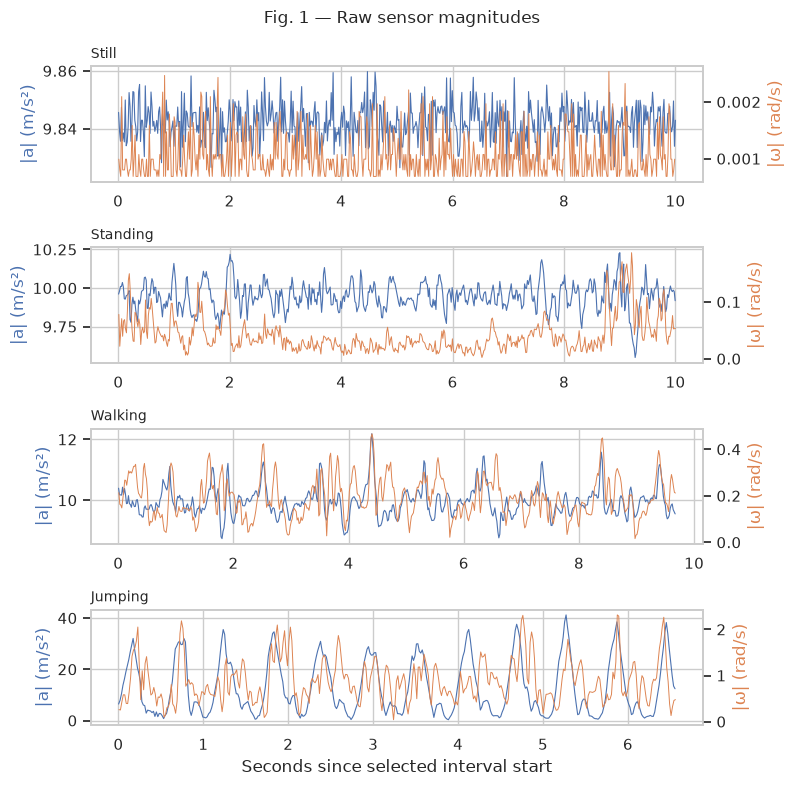

In [10]:
rep_clips = {"still": "still_03", "standing": "standing_03",
             "walking": "walking_03", "jumping": "jumping_03"}

def raw_crop(name, sensor):
    rec = next(r for r in clips if r["name"] == name)
    bounds = result["crops"].set_index("file").loc[name]
    df = rec[sensor]
    return df[df.t.between(bounds.start_s, bounds.end_s)], bounds.start_s

fig, axes = plt.subplots(4, 1, figsize=(8, 8))
for ax, activity in zip(axes, ACTIVITIES):
    acc, origin = raw_crop(rep_clips[activity], "acc")
    gyro, _ = raw_crop(rep_clips[activity], "gyro")
    second = ax.twinx()
    ax.plot(acc.t - origin, np.linalg.norm(acc[["x", "y", "z"]], axis=1), color="C0", lw=.8)
    second.plot(gyro.t - origin, np.linalg.norm(gyro[["x", "y", "z"]], axis=1), color="C1", lw=.7)
    ax.set_ylabel("|a| (m/s²)", color="C0")
    second.set_ylabel("|ω| (rad/s)", color="C1")
    second.grid(False)
    ax.set_title(activity.capitalize(), loc="left", fontsize=10)
axes[-1].set_xlabel("Seconds since selected interval start")
fig.suptitle("Fig. 1 — Raw sensor magnitudes", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_raw_signals.png", dpi=200, bbox_inches="tight")
plt.show()

### 2.6 All six native axes, by activity (notebook only)

Gravity orientation distinguishes the collection setups. This cue depends on
holding the phone consistently and should be discussed as a limitation.

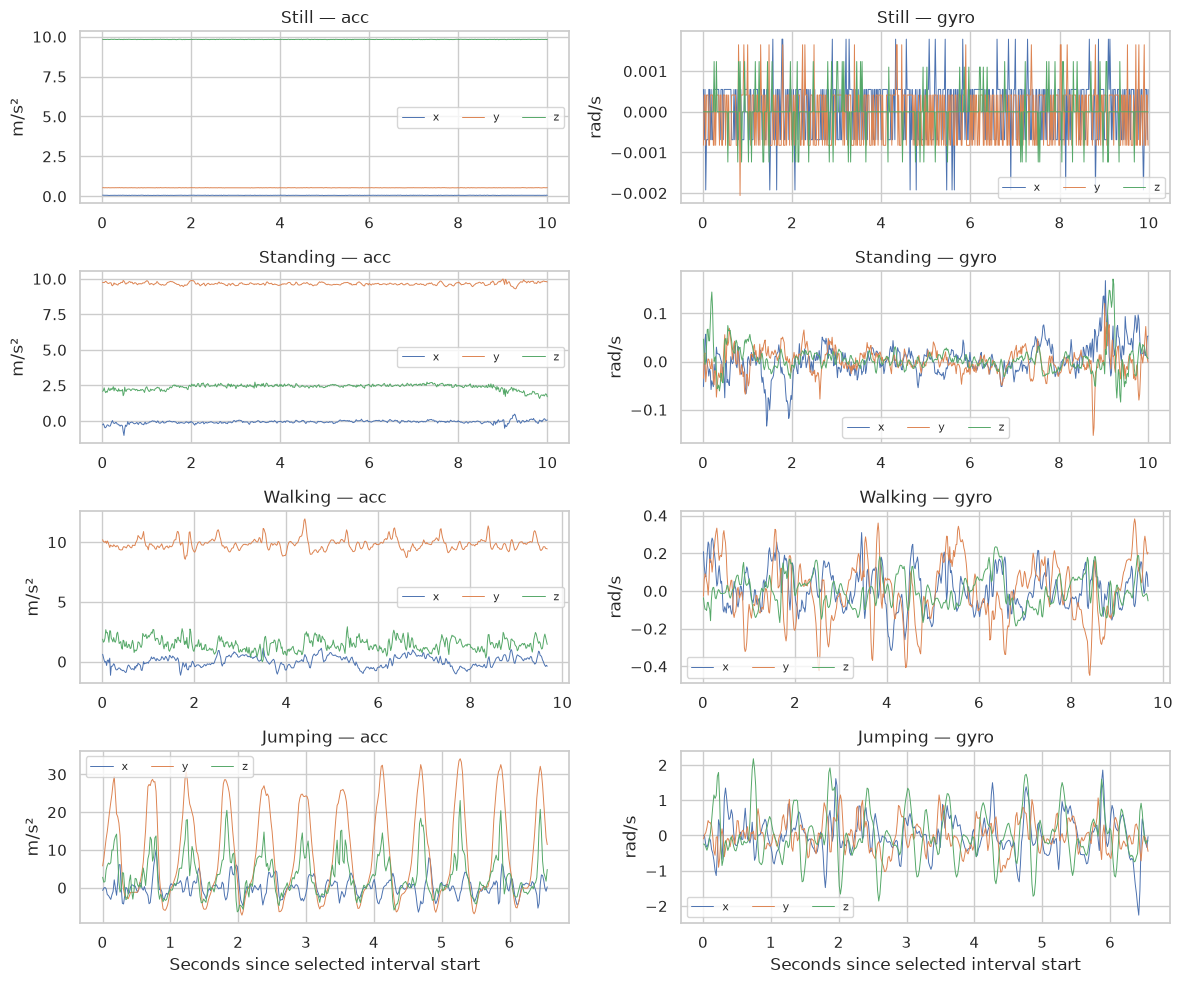

In [11]:
fig, axes = plt.subplots(4, 2, figsize=(12, 10))
for i, activity in enumerate(ACTIVITIES):
    for j, sensor in enumerate(SENSOR_FILES):
        df, origin = raw_crop(rep_clips[activity], sensor)
        for axis in "xyz":
            axes[i, j].plot(df.t - origin, df[axis], label=axis, lw=.7)
        axes[i, j].set_title(f"{activity.capitalize()} — {sensor}")
        axes[i, j].set_ylabel("m/s²" if sensor == "acc" else "rad/s")
        axes[i, j].legend(ncol=3, fontsize=8)
for ax in axes[-1]: ax.set_xlabel("Seconds since selected interval start")
fig.tight_layout()
plt.show()

### 2.7 Sampling interval and retained-duration plots (notebook only)

The histogram covers both sensors in **all 52 clips**. Session outages are listed
separately above rather than hidden in a narrow histogram. Plot bins are fixed
in milliseconds so floating-point noise cannot exaggerate tiny timing changes.

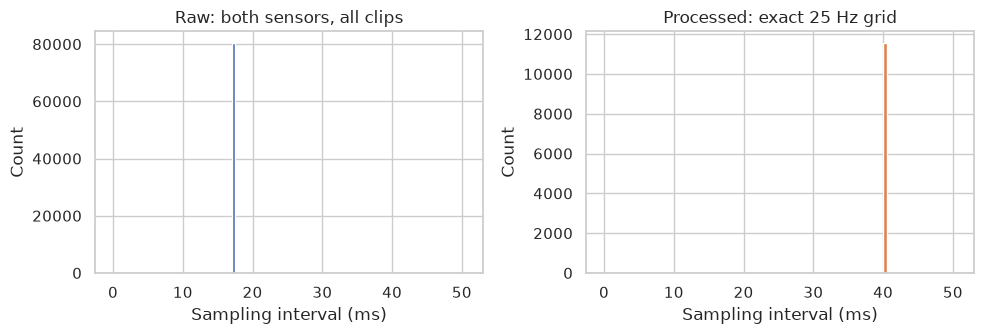

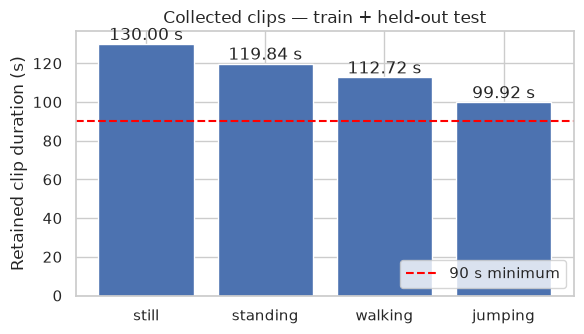

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
raw_dt = np.concatenate([np.diff(r[s].timestamp_ns.to_numpy()) / 1e6 for r in clips for s in SENSOR_FILES])
new_dt = np.concatenate([np.diff(r["df"].timestamp_ns.to_numpy()) / 1e6 for r in processed_clips])
axes[0].hist(raw_dt, bins=np.arange(0, 51, .5), color="C0")
axes[1].hist(new_dt, bins=np.arange(0, 51, .5), color="C1")
for ax, title in zip(axes, ["Raw: both sensors, all clips", "Processed: exact 25 Hz grid"]):
    ax.set(title=title, xlabel="Sampling interval (ms)", ylabel="Count")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
values = [result["status"]["clip_seconds_per_activity"][a] for a in ACTIVITIES]
bars = ax.bar(ACTIVITIES, values)
ax.axhline(90, color="red", ls="--", label="90 s minimum")
ax.bar_label(bars, fmt="%.2f s")
ax.set(ylabel="Retained clip duration (s)", title="Collected clips — train + held-out test")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 2.8 Session diagnostics and label review (notebook only)

These figures show **raw session diagnostics, not supervised ground truth**. Dark spans are
missing data; lines break at outages. Existing label boundaries are provisional,
not independently verified truth. No session shown here is automatically admitted
by inspecting its plot. Session 1's walking onset and changed orientation need
recording evidence that is unavailable; session 2 is largely missing and has no segment table. Only continuous portions are retained, without labels.

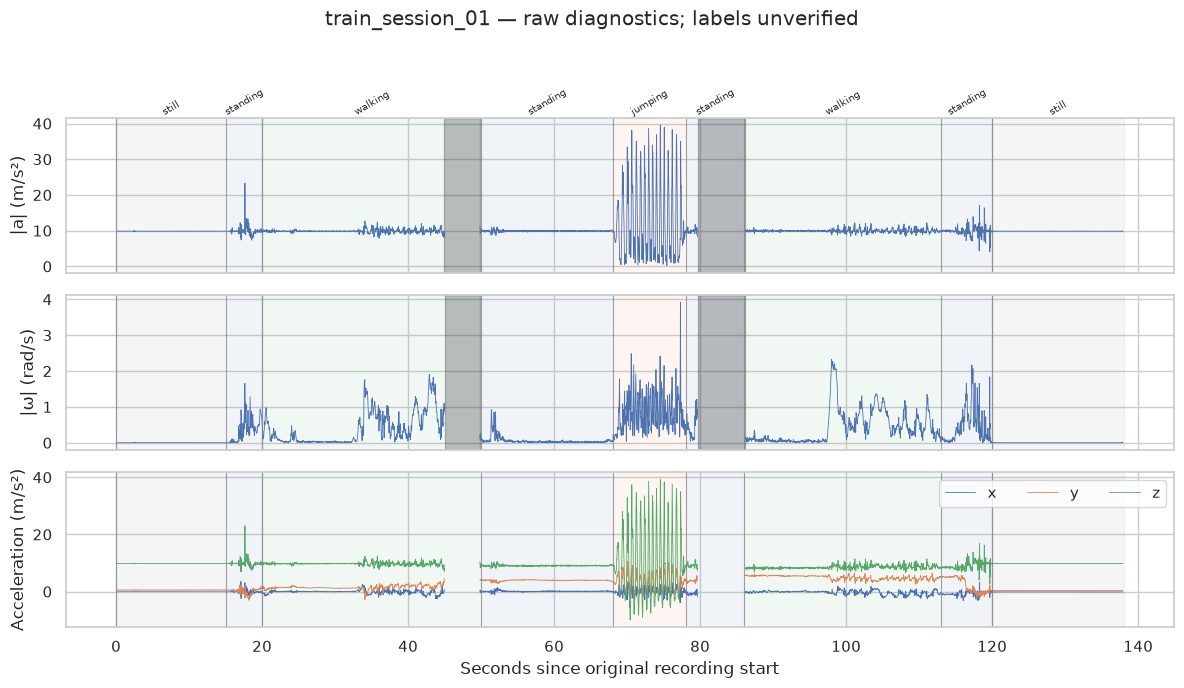

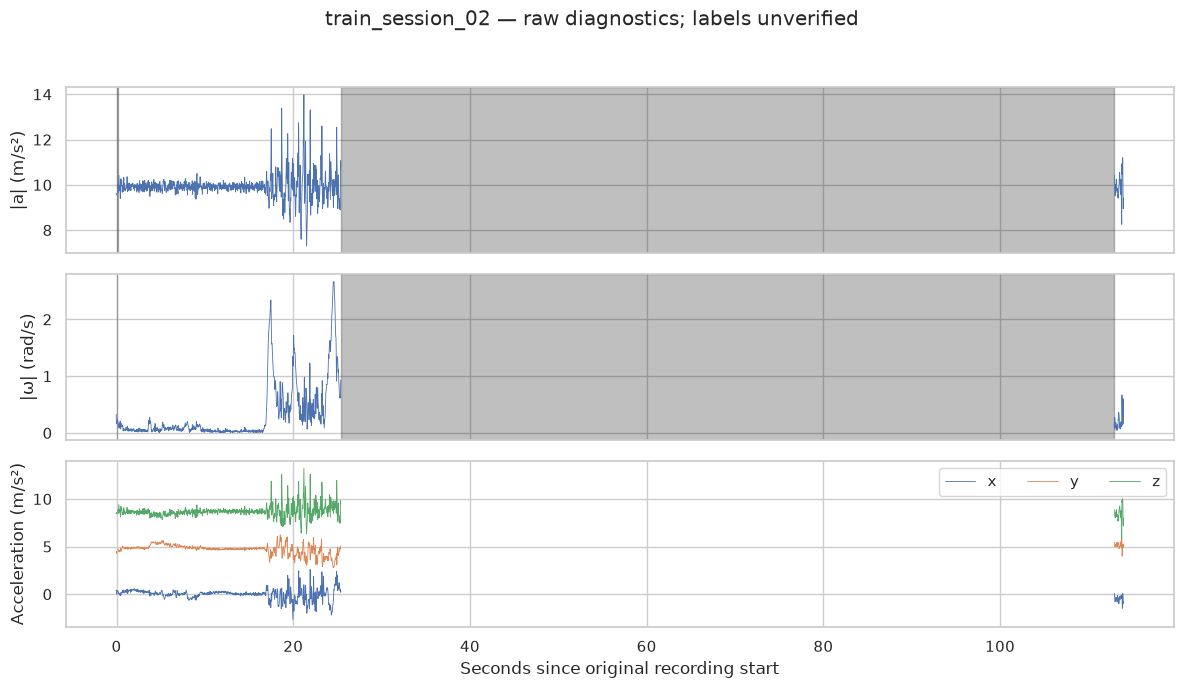

,recording,start_s,activity,mean_acc_x,mean_acc_y,mean_acc_z
0,train_session_01,0.0,still,0.123,0.569,9.824
1,train_session_01,15.0,standing,0.050,0.191,9.847
2,train_session_01,20.0,walking,-0.111,1.511,9.715
3,train_session_01,50.0,standing,0.097,3.928,9.082
4,train_session_01,68.0,jumping,0.179,3.087,9.296
5,train_session_01,78.0,standing,-0.753,3.723,9.077
6,train_session_01,86.0,walking,-0.304,4.936,8.557
7,train_session_01,113.0,standing,-0.728,2.413,9.148
8,train_session_01,120.0,still,-0.130,0.390,9.831


Compare standing clips (mean gravity predominantly on y) with the rejected session's z-dominant grip.


In [13]:
colours = {"still": "grey", "standing": "C0", "walking": "C2", "jumping": "C1"}
orientation_rows = []
for rec in sessions:
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    for i, sensor in enumerate(SENSOR_FILES):
        df = rec[sensor]
        values = np.linalg.norm(df[["x", "y", "z"]], axis=1)
        gap_indices = np.flatnonzero(np.diff(df.timestamp_ns) > 3 * np.median(np.diff(df.timestamp_ns)))
        values[gap_indices] = np.nan
        axes[i].plot(df.t, values, lw=.6)
        axes[i].set_ylabel("|a| (m/s²)" if sensor == "acc" else "|ω| (rad/s)")
        for gap in gap_intervals(df):
            axes[i].axvspan(gap["start_s"], gap["end_s"], color="black", alpha=.25)
    df = rec["acc"]
    for axis in "xyz":
        values = df[axis].to_numpy().copy()
        values[np.flatnonzero(np.diff(df.timestamp_ns) > 3 * np.median(np.diff(df.timestamp_ns)))] = np.nan
        axes[2].plot(df.t, values, label=axis, lw=.6)
    axes[2].set_ylabel("Acceleration (m/s²)")
    axes[2].legend(ncol=3)
    label_path = LABELS_DIR / f"{rec['name']}.csv"
    if label_path.exists():
        for seg in pd.read_csv(label_path).itertuples():
            for ax in axes:
                ax.axvspan(seg.start_s, seg.end_s, color=colours[seg.activity], alpha=.08)
                ax.axvline(seg.start_s, color="grey", lw=.5)
            axes[0].text((seg.start_s+seg.end_s)/2, 1.02, seg.activity,
                         transform=axes[0].get_xaxis_transform(), ha="center", fontsize=7, rotation=30)
            selected = df[df.t.between(seg.start_s, seg.end_s, inclusive="left")]
            orientation_rows.append({"recording": rec["name"], "start_s": seg.start_s,
                                     "activity": seg.activity, **{f"mean_acc_{a}": selected[a].mean() for a in "xyz"}})
    axes[-1].set_xlabel("Seconds since original recording start")
    fig.suptitle(f"{rec['name']} — raw diagnostics; labels unverified")
    fig.tight_layout(rect=[0, 0, 1, .95])
    fig.savefig(FIG_DIR / f"{rec['name']}_quality.png", dpi=150)
    plt.show()
display(pd.DataFrame(orientation_rows))
print("Compare standing clips (mean gravity predominantly on y) with the rejected session's z-dominant grip.")

### 2.9 Recoverable session blocks

Each file below preserves its original timestamp origin, has exact 25 Hz spacing,
and was filtered independently. The CSV schema deliberately omits `activity`.
Approximate original labels remain only in `data/labels/` for diagnostics. Source
fingerprints and the retained bounds are saved in the sequence manifest.
The shifted phone orientation is a distribution difference to discuss, not a
reason to invent an axis transformation or claim these recordings are equivalent
to the fixed-grip clips.

In [14]:
display(result["block_manifest"])
for block in result["unlabelled"]:
    df = pd.read_csv(PROCESSED_DIR / "unlabelled/sessions" / f"{block['name']}.csv")
    assert "activity" not in df.columns
    assert np.all(np.diff(df.timestamp_ns) == 40_000_000)
    assert np.isfinite(df.select_dtypes("number")).all().all()
print("PASS — no labels or cross-gap continuity are fabricated")

,sequence,recording,start_s,end_s,duration_s,n_samples,source_sha256,label_status
0,train_session_01_part01,train_session_01,1.131,43.931,42.80,1071,bc523de5635f7944705fd9b7c9354302a1f998b5d143ff...,unverified; no labels exported
1,train_session_01_part02,train_session_01,50.836,78.596,27.76,695,bc523de5635f7944705fd9b7c9354302a1f998b5d143ff...,unverified; no labels exported
2,train_session_01_part03,train_session_01,87.207,136.887,49.68,1243,bc523de5635f7944705fd9b7c9354302a1f998b5d143ff...,unverified; no labels exported
3,train_session_02_part01,train_session_02,1.134,24.374,23.24,582,16ffdc7ec3b61c3adabad31c0b38a88298a7b302f9d0b2...,unverified; no labels exported


PASS — no labels or cross-gap continuity are fabricated


### 2.10 Collection readiness under the revised strategy

The **44 training clips** support supervised emission initialisation. The eight held-out clips must not be used for fitting or tuning. Session activity
boundaries remain unverified, so they must not be used for labelled transition
counts or accuracy metrics. Later HMM work can use an explicit persistence prior
and optionally Baum–Welch on the independent unlabelled blocks. Keep each file
as a separate sequence; never join across gaps or across recordings.

`require_training_ready()` and `python scripts/preprocessing.py --require-complete`
validate all 52 collected clips and the fixed 44-training/8-test partition. Passing
them does **not** certify the four videos, session ground truth, or broader generalisation beyond the held-out clips.

All four video links are received; unauthenticated metadata and preview access
succeeded. Full-body framing issues remain, and active logging/full playback are
not verified. See `docs/video_review.md` and `docs/collection_completion.md`.

In [15]:
require_training_ready(result["status"])
print("PASS — labelled clip dataset ready under the revised no-re-recording strategy")
print(f"Optional unlabelled sequences: {len(result['unlabelled'])}")
print("Session ground-truth labels: NOT VERIFIED; exclude from supervised transitions and accuracy")
print(result["status"]["video_verification"])

PASS — labelled clip dataset ready under the revised no-re-recording strategy
Optional unlabelled sequences: 4
Session ground-truth labels: NOT VERIFIED; exclude from supervised transitions and accuracy
External evidence required; not certified by this pipeline


## 3. Phase 4 — fixed recording-level holdout

The participant intended the 52 single-activity recordings to supply both training
and test data. Before feature extraction or model fitting, **two entire recordings
per activity** were selected with NumPy's `default_rng(42)`, sampling without
replacement from sorted names in the order still, standing, walking, jumping.
The chosen membership is frozen in `data/split_manifest.csv`; rerunning this
notebook validates it and never selects a new split.

This yields **44 training clips (11 per activity)** and **8 test clips (2 per
activity)**. The collected dataset still has 52 files and at least 90 seconds per
activity; those are collection totals, not training-only totals. Original files
remain in `data/raw/clips/` with their unchanged activity labels. The metadata
and manifest determine membership; directory ancestry alone does not.

The test clips were already inspected and cropped during quality assurance.
Filtering/cropping are now fixed and remain unchanged. No HMM, feature selector,
normaliser, state mapping or hyperparameter search was fitted before this split.
From this point, all learned choices use only the training partition. Use
training-only validation to compare features or models; evaluate the test set at
the end. Do not claim that these clips were untouched by all exploratory work.

The original proposal of two new mixed-activity sessions at different dates and
native rates is replaced by eight independent held-out single-activity files.
They assess recognition within the existing single-person/device collection,
not generalisation to a different day/place or real cross-activity transitions.
Do not join the test clips into a fabricated continuous activity sequence.
All main clips use the configured 100 Hz setting; the lower-rate pilot is a
preprocessing demonstration only, not unseen evaluation data.

In [16]:
manifest = result["split_manifest"]
split_counts = manifest.groupby(["activity", "split"]).size().unstack().reindex(ACTIVITIES)
assert (split_counts["train"] == 11).all()
assert (split_counts["test"] == 2).all()
display(split_counts)
display(manifest.loc[manifest.split == "test", ["activity", "split", "seed"]])
# File-level validation only: no learned statistics or predictions on test data.
training_sequences = load_labelled_sequences(ROOT, "train")
test_sequences = load_labelled_sequences(ROOT, "test")
assert len(training_sequences) == 44 and len(test_sequences) == 8
assert not ({name for name, _ in training_sequences} & {name for name, _ in test_sequences})
print("PASS: fixed 44/8 split; source fingerprints and output membership verified")
print("Keep every file as an independent sequence when windowing and decoding.")

split,test,train
activity,,
still,2,11
standing,2,11
walking,2,11
jumping,2,11


,activity,split,seed
file,,,
still_02,still,test,42
still_11,still,test,42
standing_06,standing,test,42
standing_13,standing,test,42
walking_02,walking,test,42
walking_10,walking,test,42
jumping_02,jumping,test,42
jumping_07,jumping,test,42


PASS: fixed 44/8 split; source fingerprints and output membership verified
Keep every file as an independent sequence when windowing and decoding.


### 3.1 Split provenance and collection conditions

The table records actual dates, location types and rates, without inventing a new
location/day or a lower-rate test acquisition. Unlabelled session blocks belong
only to the optional training pool. Their raw time spans are checked against the
held-out recordings to guard against reuse under another filename.

In [17]:
metadata = pd.read_csv(ROOT / "data/metadata.csv").set_index("file")
test_details = metadata.loc[manifest.index[manifest.split == "test"],
                            ["activity", "date", "location_type", "configured_hz", "measured_acc_hz", "measured_gyro_hz"]]
display(test_details)
display(result["crops"].groupby(["activity", "split"]).agg(
    files=("file", "size"), seconds=("duration_s", "sum")))
assert set(metadata.loc[manifest.index, "split"]) == {"train", "test"}
assert (metadata.loc[manifest.index, "split"] == manifest["split"]).all()
print("Phase 4 complete for the revised held-out-clip design.")
print("Video framing compliance remains open; no continuous-transition test claim is made.")

,activity,date,location_type,configured_hz,measured_acc_hz,measured_gyro_hz
file,,,,,,
still_02,still,2026-10-28,indoor,100.0,58.456,58.456
still_11,still,2026-10-28,indoor,100.0,58.453,58.453
standing_06,standing,2026-10-25,indoor,100.0,58.455,58.455
standing_13,standing,2026-10-27,indoor,100.0,58.439,58.439
walking_02,walking,2026-10-25,indoor,100.0,58.457,58.457
walking_10,walking,2026-10-27,indoor,100.0,58.446,58.446
jumping_02,jumping,2026-10-27,indoor,100.0,58.446,58.446
jumping_07,jumping,2026-10-27,indoor,100.0,58.448,58.448


files  seconds
activity split                
jumping  test       2    13.12
         train     11    86.80
standing test       2    20.00
         train     11    99.84
still    test       2    20.00
         train     11   110.00
walking  test       2    19.96
         train     11    92.76

Phase 4 complete for the revised held-out-clip design.
Video framing compliance remains open; no continuous-transition test claim is made.
